# Spectral Clustering and Mean Shift

This notebook covers two clustering approaches that do not rely on assigning each point to its nearest Euclidean centroid in the original feature space.

## Part A — Spectral clustering

### Definition and intuition
Spectral clustering represents samples as a weighted graph, where edge weights express similarity. It computes eigenvectors of a graph Laplacian, embeds the points in a lower-dimensional spectral space, and clusters that embedding (often with K-means). This can reveal non-convex clusters when graph connectivity captures the structure.

### Mathematics
Given affinity matrix $W$, degree matrix $D_{ii}=\sum_j W_{ij}$, an unnormalized Laplacian is $L=D-W$. A normalized version is $L_{\mathrm{sym}}=I-D^{-1/2}WD^{-1/2}$. Low-eigenvalue eigenvectors encode graph connectivity; clustering the rows of an embedding formed from selected eigenvectors is the core idea.

The graph construction is crucial. A poor similarity scale or neighbor graph produces a poor embedding. Spectral clustering is not a universal solution and dense affinity matrices are expensive.

## Part B — Mean Shift

### Definition and intuition
Mean Shift repeatedly moves each current point toward the weighted mean of nearby data under a kernel (often a flat or Gaussian kernel). Points that converge to the same density mode form a cluster. The bandwidth sets the neighborhood scale.

### Why it can work
For common kernel-density estimates, the mean-shift vector is related to the gradient of estimated density, so steps tend to move toward modes under suitable kernels and conditions. Convergence depends on the kernel, bandwidth and data; bandwidth choice can merge or fragment clusters.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_blobs
from sklearn.cluster import SpectralClustering, MeanShift, estimate_bandwidth, KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import kneighbors_graph

SEED = 42
X_moons, y_moons = make_moons(n_samples=450, noise=0.06, random_state=SEED)
X_blobs, y_blobs = make_blobs(n_samples=500, centers=4, cluster_std=0.6, random_state=SEED)


## 1. Spectral clustering from scratch (small data)

We build a fully connected RBF affinity matrix, compute the normalized graph Laplacian eigenvectors, row-normalize the embedding, and apply K-means. Dense eigendecomposition is cubic in n, so this from-scratch implementation is only for small datasets.

In [2]:
def spectral_cluster_scratch(X, n_clusters, gamma=1.0, random_state=42):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or len(X) == 0 or not np.isfinite(X).all():
        raise ValueError("X must be a non-empty finite 2D array")
    if not 1 <= n_clusters <= len(X) or gamma <= 0:
        raise ValueError("Invalid n_clusters or gamma")
    sq = np.sum(X*X, axis=1)
    d2 = np.maximum(sq[:,None] + sq[None,:] - 2*X@X.T, 0)
    W = np.exp(-gamma*d2)
    np.fill_diagonal(W, 0)
    degree = W.sum(axis=1)
    inv_sqrt = 1 / np.sqrt(np.maximum(degree, 1e-12))
    Lsym = np.eye(len(X)) - inv_sqrt[:,None]*W*inv_sqrt[None,:]
    eigvals, eigvecs = np.linalg.eigh(Lsym)
    embedding = eigvecs[:, :n_clusters]
    norms = np.linalg.norm(embedding, axis=1, keepdims=True)
    embedding = embedding / np.maximum(norms, 1e-12)
    labels = KMeans(n_clusters=n_clusters, n_init=10, random_state=random_state).fit_predict(embedding)
    return labels, eigvals[:n_clusters], W

small_moons = X_moons[:260]
small_y = y_moons[:260]
t0 = time.perf_counter()
spec_labels, eigvals, affinity = spectral_cluster_scratch(small_moons, 2, gamma=5.0, random_state=SEED)
print("Scratch spectral ARI on 260 points:", round(adjusted_rand_score(small_y, spec_labels), 4))
print("Smallest Laplacian eigenvalues:", np.round(eigvals, 4))


Scratch spectral ARI on 260 points: 0.4253
Smallest Laplacian eigenvalues: [-0.      0.0355]


## 2. Compare with scikit-learn spectral clustering

Scratch spectral ARI: 0.4253
sklearn spectral ARI: 0.4561
K-means ARI: 0.2789


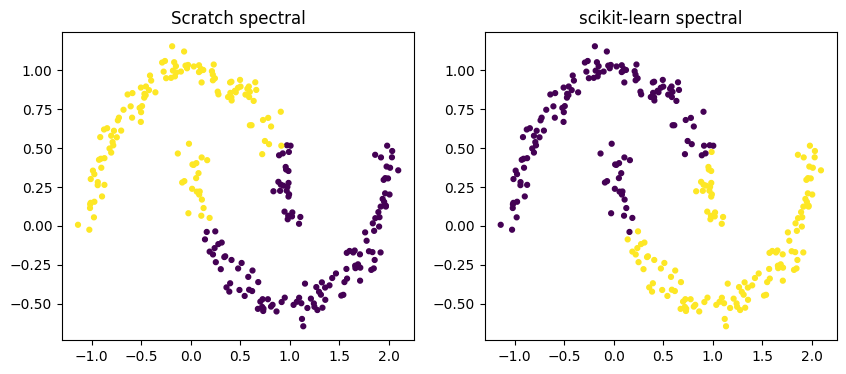

In [3]:
sk_spec = SpectralClustering(n_clusters=2, affinity="rbf", gamma=5.0, assign_labels="kmeans",
                             n_init=10, random_state=SEED).fit_predict(small_moons)
km_labels = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(small_moons)
print("Scratch spectral ARI:", round(adjusted_rand_score(small_y, spec_labels), 4))
print("sklearn spectral ARI:", round(adjusted_rand_score(small_y, sk_spec), 4))
print("K-means ARI:", round(adjusted_rand_score(small_y, km_labels), 4))
fig, ax = plt.subplots(1, 2, figsize=(10,4))
ax[0].scatter(small_moons[:,0], small_moons[:,1], c=spec_labels, s=12); ax[0].set_title("Scratch spectral")
ax[1].scatter(small_moons[:,0], small_moons[:,1], c=sk_spec, s=12); ax[1].set_title("scikit-learn spectral")
plt.show()


## 3. Spectral clustering complexity and tuning
- `n_clusters`: number of graph partitions requested.
- `affinity` / `gamma` / neighbor count: define the graph. Too small an RBF scale can make the graph disconnected; too large can erase local geometry.
- Dense affinity storage is $O(n^2)$, and full eigendecomposition can cost $O(n^3)$. It is generally unsuitable for millions of samples in the naive form.
- Use sparse k-nearest-neighbor graphs, approximate neighbors, Nyström methods or other scalable graph approximations where justified.
- GPU eigen-solvers may accelerate some matrix operations, but dense $O(n^2)$ memory remains a major limitation.

## 4. Mean Shift from scratch (small data)

This Gaussian-kernel implementation iteratively moves points toward local weighted means. It then merges converged seeds within a tolerance. That seed-merging step is an educational heuristic; production libraries have their own bandwidth and merging details.

In [4]:
def mean_shift_scratch(X, bandwidth, max_iter=100, tol=1e-3, merge_tol=None):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or len(X) == 0 or not np.isfinite(X).all():
        raise ValueError("X must be a non-empty finite 2D array")
    if bandwidth <= 0 or max_iter < 1 or tol < 0:
        raise ValueError("Invalid bandwidth, max_iter or tol")
    if merge_tol is None:
        merge_tol = bandwidth / 2
    shifted = X.copy()
    for _ in range(max_iter):
        max_shift = 0.0
        updated = shifted.copy()
        for i, point in enumerate(shifted):
            d2 = np.sum((X - point)**2, axis=1)
            weights = np.exp(-0.5*d2/(bandwidth**2))
            new_point = (weights[:,None]*X).sum(axis=0) / weights.sum()
            max_shift = max(max_shift, np.linalg.norm(new_point-point))
            updated[i] = new_point
        shifted = updated
        if max_shift < tol:
            break
    centers = []
    labels = np.empty(len(X), dtype=int)
    for i, point in enumerate(shifted):
        if not centers:
            centers.append(point.copy()); labels[i] = 0; continue
        distances = np.linalg.norm(np.asarray(centers)-point, axis=1)
        nearest = int(np.argmin(distances))
        if distances[nearest] <= merge_tol:
            labels[i] = nearest
        else:
            centers.append(point.copy()); labels[i] = len(centers)-1
    # A few centroids may have been created in arbitrary order; assign final labels by nearest retained center.
    centers = np.asarray(centers)
    final_dist = np.linalg.norm(shifted[:,None,:]-centers[None,:,:], axis=2)
    return centers, final_dist.argmin(axis=1), shifted

small_blobs = X_blobs[:220]
small_blob_y = y_blobs[:220]
centers_ms, labels_ms, shifted_ms = mean_shift_scratch(small_blobs, bandwidth=1.0, max_iter=40)
print("Scratch Mean Shift clusters:", len(centers_ms))
print("Scratch Mean Shift ARI on sample:", round(adjusted_rand_score(small_blob_y, labels_ms), 4))


Scratch Mean Shift clusters: 4
Scratch Mean Shift ARI on sample: 1.0


## 5. Compare Mean Shift with scikit-learn

Bandwidth dominates the result. `estimate_bandwidth` can itself be expensive on large data; consider sampling for bandwidth estimation.

Estimated bandwidth: 1.403
sklearn Mean Shift clusters: 4
sklearn Mean Shift ARI: 1.0


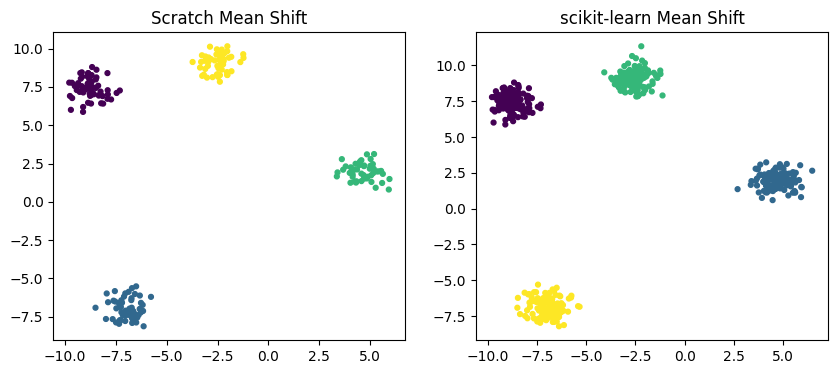

In [5]:
bandwidth = estimate_bandwidth(X_blobs, quantile=0.2, n_samples=300, random_state=SEED)
ms = MeanShift(bandwidth=bandwidth, bin_seeding=True).fit(X_blobs)
print("Estimated bandwidth:", round(float(bandwidth), 3))
print("sklearn Mean Shift clusters:", len(np.unique(ms.labels_)))
print("sklearn Mean Shift ARI:", round(adjusted_rand_score(y_blobs, ms.labels_), 4))
fig, ax = plt.subplots(1, 2, figsize=(10,4))
ax[0].scatter(small_blobs[:,0], small_blobs[:,1], c=labels_ms, s=12); ax[0].set_title("Scratch Mean Shift")
ax[1].scatter(X_blobs[:,0], X_blobs[:,1], c=ms.labels_, s=12); ax[1].set_title("scikit-learn Mean Shift")
plt.show()


## 6. Mean Shift tuning, complexity and best practices
- `bandwidth`: the key scale parameter. Small bandwidth yields many modes; large bandwidth merges modes.
- `bin_seeding`: starts from grid bins to reduce redundant seeds.
- A naive mean-shift pass costs roughly $O(n^2d)$ per iteration if every point is updated against every observation; with T iterations the cost is $O(Tn^2d)$.
- Standardize if units should contribute comparably. High dimensions and large n make dense neighborhoods expensive.
- The scratch implementation is for intuition and small data; do not use it for millions of samples.
- GPU pairwise weight calculations can be parallelized, but all-pairs memory and mode merging require design beyond a simple broadcast.

## 7. Synthesis and correctness tests
Spectral clustering uses global graph structure and eigenvectors; Mean Shift follows local density gradients toward modes. Both can discover non-centroid-shaped clusters, but their scale parameters and computational costs differ substantially.

In [6]:
assert len(spec_labels) == len(small_moons)
assert len(labels_ms) == len(small_blobs)
assert np.isfinite(centers_ms).all()
try:
    mean_shift_scratch(np.array([1,2,3]), bandwidth=1.0)
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid input shape to raise")
print("All spectral / mean-shift checks passed.")


All spectral / mean-shift checks passed.
